# ECRECOVER usage by contract and entity

#### Maria Silva, November 2026

Extracts every call to the `ECRECOVER` precompile (`0x…01`) from Xatu's `canonical_execution_transaction_structlog_agg` table, identifies the contract that made each call, and matches those contracts to entities using the merged label cache from the `repricing-impact` repo (`label_cache/contract_labels.parquet`).

This first pass runs on a small sample window (one hour of mainnet blocks). Widen `start_date_str` / `end_date_str` in Section 2 to expand it.

In [39]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sqlalchemy import URL, create_engine

In [40]:
sns.set_theme(
    style="whitegrid", palette="Set2", rc={"figure.dpi": 150, "axes.titlesize": 15}
)

# Works from the repository root, notebooks/, or another directory inside the repo.
repo_dir = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "notebooks" / "5.5-ecrecover_usage_by_entity.ipynb").is_file()),
    None,
)
if repo_dir is None:
    raise FileNotFoundError("Run this notebook from inside evm-gas-repricings.")
labels_path = repo_dir.parent / "repricing-impact" / "label_cache" / "contract_labels.parquet"

## 1. Connect to Xatu ClickHouse

In [41]:
with (repo_dir / "secrets.json").open() as file:
    secrets = json.load(file)

# URL.create also handles passwords containing URL-special characters.
engine = create_engine(URL.create(
    "clickhouse+http",
    username=secrets["xatu_username"],
    password=secrets["xatu_password"],
    host="clickhouse.xatu.ethpandaops.io",
    port=443,
    database="default",
    query={"protocol": "https"},
))

## 2. Resolve Block Bounds for the Sample Window

Resolve the sample window to a `block_number` range via `canonical_beacon_block`. The structlog table lags the chain head by a few days (at the time of writing it covered blocks up to ~26.30M, i.e. 2026-10-29), so the window must sit inside its coverage.

In [42]:
network = "mainnet"
start_date_str = "2026-10-27 00:00:00"
end_date_str = "2026-10-27 01:00:00"

block_bounds_query = f"""
SELECT
    count() AS n_beacon_blocks,
    MIN(execution_payload_block_number) AS min_block,
    MAX(execution_payload_block_number) AS max_block
FROM default.canonical_beacon_block FINAL
WHERE slot_start_date_time >= toDateTime('{start_date_str}', 'UTC')
    AND slot_start_date_time < toDateTime('{end_date_str}', 'UTC')
    AND meta_network_name = '{network}'
"""
block_bounds = pd.read_sql(block_bounds_query, con=engine).iloc[0]
if block_bounds["n_beacon_blocks"] == 0:
    raise ValueError("No beacon blocks found in the requested window.")
min_block, max_block = int(block_bounds["min_block"]), int(block_bounds["max_block"])
print(
    f"{start_date_str} to {end_date_str} -> blocks {min_block:,} to {max_block:,} "
    f"({max_block - min_block + 1:,} blocks)"
)

2026-10-27 00:00:00 to 2026-10-27 01:00:00 -> blocks 26,280,314 to 26,280,612 (299 blocks)


## 3. Extract ECRECOVER Calls

**Data source**

`canonical_execution_transaction_structlog_agg` has one *frame summary row* per call frame (`operation = ''`) plus one row per opcode per frame. Precompile calls get their own frame: an `ECRECOVER` call is a summary row with `target_address = 0x…01`, zero opcodes and `gas_cumulative = 3000`. `call_frame_path` holds the frame IDs from the root to the current frame, so the frame that *made* the call is its parent.

The table is a distributed ReplacingMergeTree with ~105B rows, sorted by `(meta_network_name, block_number, transaction_hash, call_frame_id, operation)`, so every query filters on `meta_network_name` and a `block_number` range and is pulled in chunks. For each chunk we fetch the `ECRECOVER` frames **and only their ancestor frames** (via `arrayJoin(call_frame_path)`), which is all we need to resolve the caller and the transaction's `to` address.

In [43]:
ECRECOVER_ADDRESS = "0x0000000000000000000000000000000000000001"
DELEGATING_CALL_TYPES = ["DELEGATECALL", "CALLCODE"]


def fetch_ecrecover_frames(engine, network, block_start, block_end):
    """Pull ECRECOVER frames and all their ancestor frames in [block_start, block_end].

    One row per frame summary (operation = ''). Only frames lying on the path from the
    root to an ECRECOVER call are returned, so the frame tree above each call can be
    rebuilt locally.
    """
    query = f"""
    SELECT
        block_number,
        transaction_hash,
        transaction_index,
        call_frame_id,
        parent_call_frame_id,
        depth,
        lower(target_address) AS target_address,
        call_type,
        error_count,
        gas_cumulative
    FROM default.canonical_execution_transaction_structlog_agg
    WHERE meta_network_name = '{network}'
        AND block_number BETWEEN {block_start} AND {block_end}
        AND operation = ''
        AND (transaction_hash, call_frame_id) GLOBAL IN (
            SELECT transaction_hash, arrayJoin(call_frame_path)
            FROM default.canonical_execution_transaction_structlog_agg
            WHERE meta_network_name = '{network}'
                AND block_number BETWEEN {block_start} AND {block_end}
                AND operation = ''
                AND target_address = '{ECRECOVER_ADDRESS}'
        )
    """
    return pd.read_sql(query, con=engine)

In [44]:
chunk_size = 100

frames_chunks = []
for block_start in range(min_block, max_block + 1, chunk_size):
    block_end = min(block_start + chunk_size - 1, max_block)
    frames_chunks.append(
        fetch_ecrecover_frames(engine, network, block_start, block_end)
    )
    print(f"Fetched blocks {block_start:,} to {block_end:,}")

frames_df = pd.concat(frames_chunks, ignore_index=True)
frames_df.info()

Fetched blocks 26,280,314 to 26,280,413
Fetched blocks 26,280,414 to 26,280,513
Fetched blocks 26,280,514 to 26,280,612
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31510 entries, 0 to 31509
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   block_number          31510 non-null  int64  
 1   transaction_hash      31510 non-null  object 
 2   transaction_index     31510 non-null  int64  
 3   call_frame_id         31510 non-null  int64  
 4   parent_call_frame_id  25981 non-null  float64
 5   depth                 31510 non-null  int64  
 6   target_address        31510 non-null  object 
 7   call_type             31510 non-null  object 
 8   error_count           31510 non-null  int64  
 9   gas_cumulative        31510 non-null  int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 2.4+ MB


In [45]:
frame_keys = ["block_number", "transaction_hash", "call_frame_id"]


def deduplicate_frames(frames):
    """Remove identical copies, but never choose arbitrarily between versions."""
    unique = frames.drop_duplicates()
    if unique.duplicated(frame_keys).any():
        raise ValueError("Conflicting frame versions; resolve them at the source.")
    return unique.reset_index(drop=True)


n_rows = len(frames_df)
frames_df = deduplicate_frames(frames_df)
print(f"Identical duplicate frames removed: {n_rows - len(frames_df):,}")

Identical duplicate frames removed: 0


### 3.1 Resolve the calling contract

An `ECRECOVER` call may happen several contracts deep inside a transaction. We record three addresses to distinguish where the transaction started, which contract invoked ECRECOVER, and whose account that contract was running as.

| Field | Meaning |
|---|---|
| **`tx_to_address`** | Where the transaction started: the root frame's target. Usually this is the transaction destination; for a contract-creation transaction, it is the created contract. |
| **`parent_target_address`** | The target of the frame that directly invoked ECRECOVER. Usually this is the address containing the code that made the call, subject to the EIP-7702 caveat below. |
| **`context_address`** | The account that the invoking code was running as: the address returned by `address(this)`, whose storage it uses. |

**Example: a Uniswap swap using a Permit2 signature**

For an ordinary wallet signature, the relevant call chain can be:

```text
Transaction → Uniswap Router → Permit2 → ECRECOVER
```

Here `tx_to_address` is the **Router**, while both `parent_target_address` and `context_address` are **Permit2**. Permit2 executes its own code using its own account context. The Router and Permit2 are separate contracts performing different jobs. See the [Router documentation](https://developers.uniswap.org/docs/protocols/universal-router/overview) and [Permit2 signature-checking code](https://github.com/Uniswap/permit2/blob/main/src/libraries/SignatureVerification.sol).

**Example: a proxy wallet using shared implementation code**

A proxy wallet keeps the wallet's balance and settings at one address, but uses `DELEGATECALL` to execute wallet logic stored at another address, called the implementation. Many wallets can share the same implementation while keeping their own balances and settings.

```text
Transaction → Wallet proxy → DELEGATECALL Implementation → ECRECOVER
```

Here `tx_to_address` and `context_address` are the **wallet proxy**, while `parent_target_address` is the **implementation**. The implementation supplies the code, and that code reads the proxy's settings and acts as the proxy.

To resolve this distinction, frames entered through `DELEGATECALL` or `CALLCODE` inherit their parent's context address. Frames entered through `CALL` or `STATICCALL` use their own target address. The root starts with its own target address. We then attach the invoking parent frame's target and context to each ECRECOVER call. When parent target and context are the same address, label matching selects the parent target. When they differ, it prefers the context label and falls back to the parent target; that fallback can identify a shared implementation rather than the owner of an individual proxy.

**Limitations and checks**

- With **EIP-7702**, a target can be a delegated EOA executing code from another address. This extract does not resolve that code address, so `parent_target_address` is not always the address supplying the code.
- A transaction sent directly to `0x…01` has a `tx_to_address` but no calling contract; its parent target and context are missing.
- Missing ancestors for any other call are rejected as incomplete data. Missing whole transactions or blocks cannot be detected from this ancestor-only extract.
- Counts include failed calls and calls in reverted execution. They measure observed precompile invocations, not successful signature validations.


In [46]:
def add_context_address(frames_df):
    """Resolve contexts top-down, checking that every non-root has its parent."""
    frames = frames_df.sort_values("depth").copy()
    contexts = {}
    for row in frames.itertuples(index=False):
        key = (row.block_number, row.transaction_hash, row.call_frame_id)
        if row.call_frame_id == 0:
            if pd.notna(row.parent_call_frame_id):
                raise ValueError(f"Root has a parent: {key}")
        else:
            parent = (row.block_number, row.transaction_hash, row.parent_call_frame_id)
            if parent not in contexts:
                raise ValueError(f"Missing or out-of-order parent for frame {key}")
        contexts[key] = (
            contexts[parent] if row.call_type in DELEGATING_CALL_TYPES
            else row.target_address
        )
    frames["context_address"] = [
        contexts[key] for key in frames[frame_keys].itertuples(index=False, name=None)
    ]
    return frames


def build_ecrecover_calls(frames_df):
    """One row per observed invocation, with caller and transaction attribution."""
    frames = add_context_address(deduplicate_frames(frames_df))
    frames["parent_call_frame_id"] = frames["parent_call_frame_id"].astype("Int64")
    calls = frames.loc[frames["target_address"].eq(ECRECOVER_ADDRESS), [
        *frame_keys, "transaction_index", "parent_call_frame_id", "depth",
        "call_type", "error_count",
    ]].rename(columns={"call_type": "ecrecover_call_type"})
    calls["is_direct_tx"] = calls["call_frame_id"].eq(0)

    parents = frames[[*frame_keys, "target_address", "call_type", "context_address"]].rename(
        columns={"call_frame_id": "parent_call_frame_id",
                 "target_address": "parent_target_address",
                 "call_type": "parent_call_type"}
    )
    roots = frames.loc[frames["call_frame_id"].eq(0), [
        *frame_keys[:2], "target_address",
    ]].rename(columns={"target_address": "tx_to_address"})
    calls = calls.merge(
        parents, on=[*frame_keys[:2], "parent_call_frame_id"],
        how="left", validate="many_to_one",
    ).merge(roots, on=frame_keys[:2], how="left", validate="many_to_one")
    if calls["tx_to_address"].isna().any():
        raise ValueError("Missing transaction root for an ECRECOVER frame.")
    if calls.loc[~calls["is_direct_tx"], "parent_target_address"].isna().any():
        raise ValueError("Missing caller target for a non-root ECRECOVER frame.")
    calls["parent_call_type"] = calls["parent_call_type"].replace("", "TX")
    return calls.sort_values(
        ["block_number", "transaction_index", "call_frame_id"]
    ).reset_index(drop=True)

In [47]:
ecrecover_df = build_ecrecover_calls(frames_df)
ecrecover_df.info()
display(ecrecover_df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13466 entries, 0 to 13465
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   block_number           13466 non-null  int64 
 1   transaction_hash       13466 non-null  object
 2   call_frame_id          13466 non-null  int64 
 3   transaction_index      13466 non-null  int64 
 4   parent_call_frame_id   13466 non-null  Int64 
 5   depth                  13466 non-null  int64 
 6   ecrecover_call_type    13466 non-null  object
 7   error_count            13466 non-null  int64 
 8   is_direct_tx           13466 non-null  bool  
 9   parent_target_address  13466 non-null  object
 10  parent_call_type       13466 non-null  object
 11  context_address        13466 non-null  object
 12  tx_to_address          13466 non-null  object
dtypes: Int64(1), bool(1), int64(5), object(6)
memory usage: 1.3+ MB


,block_number,transaction_hash,call_frame_id,transaction_index,parent_call_frame_id,depth,ecrecover_call_type,error_count,is_direct_tx,parent_target_address,parent_call_type,context_address,tx_to_address
0,26280314,0x4e108e3375d0f180f010cfa21deb161e34f0fe09d662...,18,0,2,3,STATICCALL,0,False,0x0000000aa232009084bd71a5797d089aa4edfad4,CALL,0x0000000aa232009084bd71a5797d089aa4edfad4,0x0000000aa232009084bd71a5797d089aa4edfad4
1,26280314,0x4e108e3375d0f180f010cfa21deb161e34f0fe09d662...,22,0,2,3,STATICCALL,0,False,0x0000000aa232009084bd71a5797d089aa4edfad4,CALL,0x0000000aa232009084bd71a5797d089aa4edfad4,0x0000000aa232009084bd71a5797d089aa4edfad4
2,26280314,0x2f87e0975f308080b9ef82ef4d85a94c722656825884...,91,3,90,5,STATICCALL,0,False,0x98ab855dac8dcc24e47f1f5dbf68561ce412dc40,STATICCALL,0x98ab855dac8dcc24e47f1f5dbf68561ce412dc40,0x4ebc36dcee3ca916ff4157b51c2a16105a3774b5
3,26280314,0x7c0aff41329352d1b72128d6ab3bad646bfeb1067930...,2,26,1,2,STATICCALL,0,False,0x471a8de3eec36775d230070f9704cc86bf0f360d,DELEGATECALL,0x88649f4743a758171077b98ee2003f1989b1615a,0x88649f4743a758171077b98ee2003f1989b1615a
4,26280314,0x7c0aff41329352d1b72128d6ab3bad646bfeb1067930...,24,26,23,9,STATICCALL,0,False,0xd7a5c6b52756e795f680b0f7e0c2f21281dde6ef,DELEGATECALL,0x8f10b468b06c6fd214b65f87778827f7d113f996,0x88649f4743a758171077b98ee2003f1989b1615a


In [48]:
if ecrecover_df.empty:
    raise ValueError("No ECRECOVER frames found; check the window and source coverage.")

n_blocks = max_block - min_block + 1
n_txs = ecrecover_df["transaction_hash"].nunique()
# Exclude direct transactions, which have no calling contract.
different_context = (
    ecrecover_df["parent_target_address"].notna()
    & ecrecover_df["context_address"].notna()
    & ecrecover_df["parent_target_address"].ne(ecrecover_df["context_address"])
)
print(f"ECRECOVER calls: {len(ecrecover_df):,} ({len(ecrecover_df) / n_blocks:.1f} per block)")
print(f"Transactions with >= 1 call: {n_txs:,} ({n_txs / n_blocks:.1f} per block)")
for col in ["parent_target_address", "context_address", "tx_to_address"]:
    print(f"Unique {col}: {ecrecover_df[col].nunique():,}")
print(f"Transactions sent directly to 0x01: {ecrecover_df['is_direct_tx'].sum():,}")
print(f"Calls with parent target != context: {different_context.sum():,}")
display(ecrecover_df["ecrecover_call_type"].value_counts().to_frame())
display(ecrecover_df["parent_call_type"].value_counts().to_frame())

ECRECOVER calls: 13,466 (45.0 per block)
Transactions with >= 1 call: 5,529 (18.5 per block)
Unique parent_target_address: 1,564
Unique context_address: 1,790
Unique tx_to_address: 867
Transactions sent directly to 0x01: 0
Calls with parent target != context: 6,143


,count
ecrecover_call_type,
STATICCALL,13408
CALL,58


,count
parent_call_type,
DELEGATECALL,6160
CALL,4568
TX,2333
STATICCALL,405


## 4. Match Contracts to Entities

The `repricing-impact` merged label cache combines the manual overrides, OLI, Dune, ethereum-lists, MEV-bot lists and heuristics into one row per address, with a display `label`, a coarse `category`, an `owner_project` and the winning `source`. We match it against the context, parent target and tx-to addresses.

Attribution selects the parent target when parent and context are the same address. When they differ, it prefers the context label and falls back to the parent target label. This fallback identifies a shared implementation, not necessarily the owner of each proxy. Contract-label and project rankings are shown separately. Cache metadata is used as supplied and needs independent validation; for example, the current cache labels `0xbbbbbbbbbb9cc5e90e3b3af64bdaf62c37eeffcb` as `0x Settler / Aggregation` but assigns `morpho-org` as its owner project.

In [49]:
labels_df = pd.read_parquet(labels_path)[
    ["address", "label", "category", "owner_project", "source"]
]
labels_df["address"] = labels_df["address"].str.lower()
# Heuristic rows whose label is just the address itself carry no entity information
labels_df = labels_df[labels_df["label"].str.lower() != labels_df["address"]]
if labels_df["address"].isna().any() or labels_df["address"].duplicated().any():
    raise ValueError("Label cache must have one non-null row per normalized address.")
labels_df.info()
display(labels_df["source"].value_counts().to_frame())

<class 'pandas.core.frame.DataFrame'>
Index: 211429 entries, 0 to 211508
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   address        211429 non-null  object
 1   label          211429 non-null  object
 2   category       211429 non-null  object
 3   owner_project  209588 non-null  object
 4   source         211429 non-null  object
dtypes: object(5)
memory usage: 9.7+ MB


,count
source,
ethlists,211266
oli,71
dune,38
manual,33
heuristic,18
mev,3


In [50]:
ADDRESS_COLUMNS = [
    ("context_address", "context"),
    ("parent_target_address", "parent"),
    ("tx_to_address", "tx_to"),
]


def add_labels(df, labels, address_col, prefix):
    renamed = labels.rename(columns={
        c: address_col if c == "address" else f"{prefix}_{c}" for c in labels.columns
    })
    return df.merge(renamed, on=address_col, how="left", validate="many_to_one")


labelled_df = ecrecover_df
for address_col, prefix in ADDRESS_COLUMNS:
    labelled_df = add_labels(labelled_df, labels_df, address_col, prefix)

def add_entity_attribution(df):
    """Prefer parent on equal addresses; otherwise context, then parent fallback."""
    df = df.copy()
    same_address = df["parent_target_address"].notna() & df["parent_target_address"].eq(
        df["context_address"]
    )
    use_parent = df["parent_label"].notna() & (
        same_address | df["context_label"].isna()
    )
    for field, output in [
        ("label", "entity"),
        ("category", "entity_category"),
        ("owner_project", "entity_owner_project"),
    ]:
        df[output] = df[f"context_{field}"].where(~use_parent, df[f"parent_{field}"])
    df["entity_matched_on"] = np.select(
        [use_parent, df["context_label"].notna()],
        ["parent_target", "context"], default="none",
    )
    df["project"] = df["entity_owner_project"].fillna(df["entity"])
    return df


labelled_df = add_entity_attribution(labelled_df)
labelled_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13466 entries, 0 to 13465
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   block_number           13466 non-null  int64 
 1   transaction_hash       13466 non-null  object
 2   call_frame_id          13466 non-null  int64 
 3   transaction_index      13466 non-null  int64 
 4   parent_call_frame_id   13466 non-null  Int64 
 5   depth                  13466 non-null  int64 
 6   ecrecover_call_type    13466 non-null  object
 7   error_count            13466 non-null  int64 
 8   is_direct_tx           13466 non-null  bool  
 9   parent_target_address  13466 non-null  object
 10  parent_call_type       13466 non-null  object
 11  context_address        13466 non-null  object
 12  tx_to_address          13466 non-null  object
 13  context_label          1255 non-null   object
 14  context_category       1255 non-null   object
 15  context_owner_proje

### 4.1 Label coverage

In [51]:
coverage_rows = []
for address_col, prefix in ADDRESS_COLUMNS:
    unique_addresses = labelled_df.dropna(subset=[address_col]).drop_duplicates(address_col)
    coverage_rows.append(
        {
            "address": address_col,
            "unique_addresses": unique_addresses[address_col].nunique(),
            "pct_addresses_labelled": 100
            * unique_addresses[f"{prefix}_label"].notna().mean(),
            "pct_calls_labelled": 100 * labelled_df[f"{prefix}_label"].notna().mean(),
        }
    )
coverage_rows.append(
    {
        "address": "contract label (parent if equal; otherwise context, else parent)",
        "unique_addresses": labelled_df["context_address"].nunique(),
        "pct_addresses_labelled": np.nan,
        "pct_calls_labelled": 100 * labelled_df["entity"].notna().mean(),
    }
)
coverage_df = pd.DataFrame(coverage_rows).round(1)
display(coverage_df)
display(labelled_df["entity_matched_on"].value_counts().to_frame())

,address,unique_addresses,pct_addresses_labelled,pct_calls_labelled
0,context_address,1790,0.8,9.3
1,parent_target_address,1564,0.8,5.4
2,tx_to_address,867,2.2,25.8
3,contract label (parent if equal; otherwise con...,1790,NaN,9.6


,count
entity_matched_on,
none,12178
parent_target,732
context,556


## 5. ECRECOVER Usage by Contract Label and Project

In [52]:
entity_summary_df = (
    labelled_df.assign(entity=labelled_df["entity"].fillna("unlabelled"))
    .groupby("entity", dropna=False)
    .agg(
        n_calls=("call_frame_id", "size"),
        n_txs=("transaction_hash", "nunique"),
        n_context_addresses=("context_address", "nunique"),
        category=("entity_category", lambda s: ", ".join(sorted(s.dropna().unique()))),
        owner_project=("entity_owner_project", lambda s: ", ".join(sorted(s.dropna().unique()))),
        matched_on=("entity_matched_on", lambda s: ", ".join(sorted(s.unique()))),
    )
    .sort_values("n_calls", ascending=False)
)
entity_summary_df["pct_calls"] = (
    100 * entity_summary_df["n_calls"] / len(labelled_df)
).round(2)
entity_summary_df["calls_per_tx"] = (
    entity_summary_df["n_calls"] / entity_summary_df["n_txs"]
).round(2)
display(entity_summary_df.head(25))

# Projects combine contract labels where the cache supplies an owner project.
project_summary_df = (
    labelled_df.assign(project=labelled_df["project"].fillna("unlabelled"))
    .groupby("project")
    .agg(n_calls=("call_frame_id", "size"),
         n_txs=("transaction_hash", "nunique"),
         n_context_addresses=("context_address", "nunique"))
    .sort_values("n_calls", ascending=False)
)
project_summary_df["pct_calls"] = (100 * project_summary_df["n_calls"] / len(labelled_df)).round(2)
display(project_summary_df.head(25))

,n_calls,n_txs,n_context_addresses,category,owner_project,matched_on,pct_calls,calls_per_tx
entity,,,,,,,,
unlabelled,12178,4969,1757,,,none,90.44,2.45
matic,400,4,1,unknown,matic,context,2.97,100.00
Uniswap Permit2,395,391,1,unknown,,parent_target,2.93,1.01
Circle USDC,133,133,1,stablecoin,circlefin,context,0.99,1.00
1inch Aggregation Router,115,109,1,swap_dex,1-inch,parent_target,0.85,1.06
GPv2Settlement,89,85,1,swap_dex,cowprotocol,parent_target,0.66,1.05
BebopSettlement,51,48,1,swap_dex,bebop-dex,parent_target,0.38,1.06
V2DutchOrderReactor,34,34,1,other,uniswap,parent_target,0.25,1.00
SafeL2,26,25,14,other,gnosis_safe,parent_target,0.19,1.04


,n_calls,n_txs,n_context_addresses,pct_calls
project,,,,
unlabelled,12178,4969,1757,90.44
matic,400,4,1,2.97
Uniswap Permit2,395,391,1,2.93
circlefin,133,133,1,0.99
1-inch,115,109,1,0.85
cowprotocol,89,85,1,0.66
bebop-dex,51,48,1,0.38
uniswap,34,34,1,0.25
gnosis_safe,26,25,14,0.19


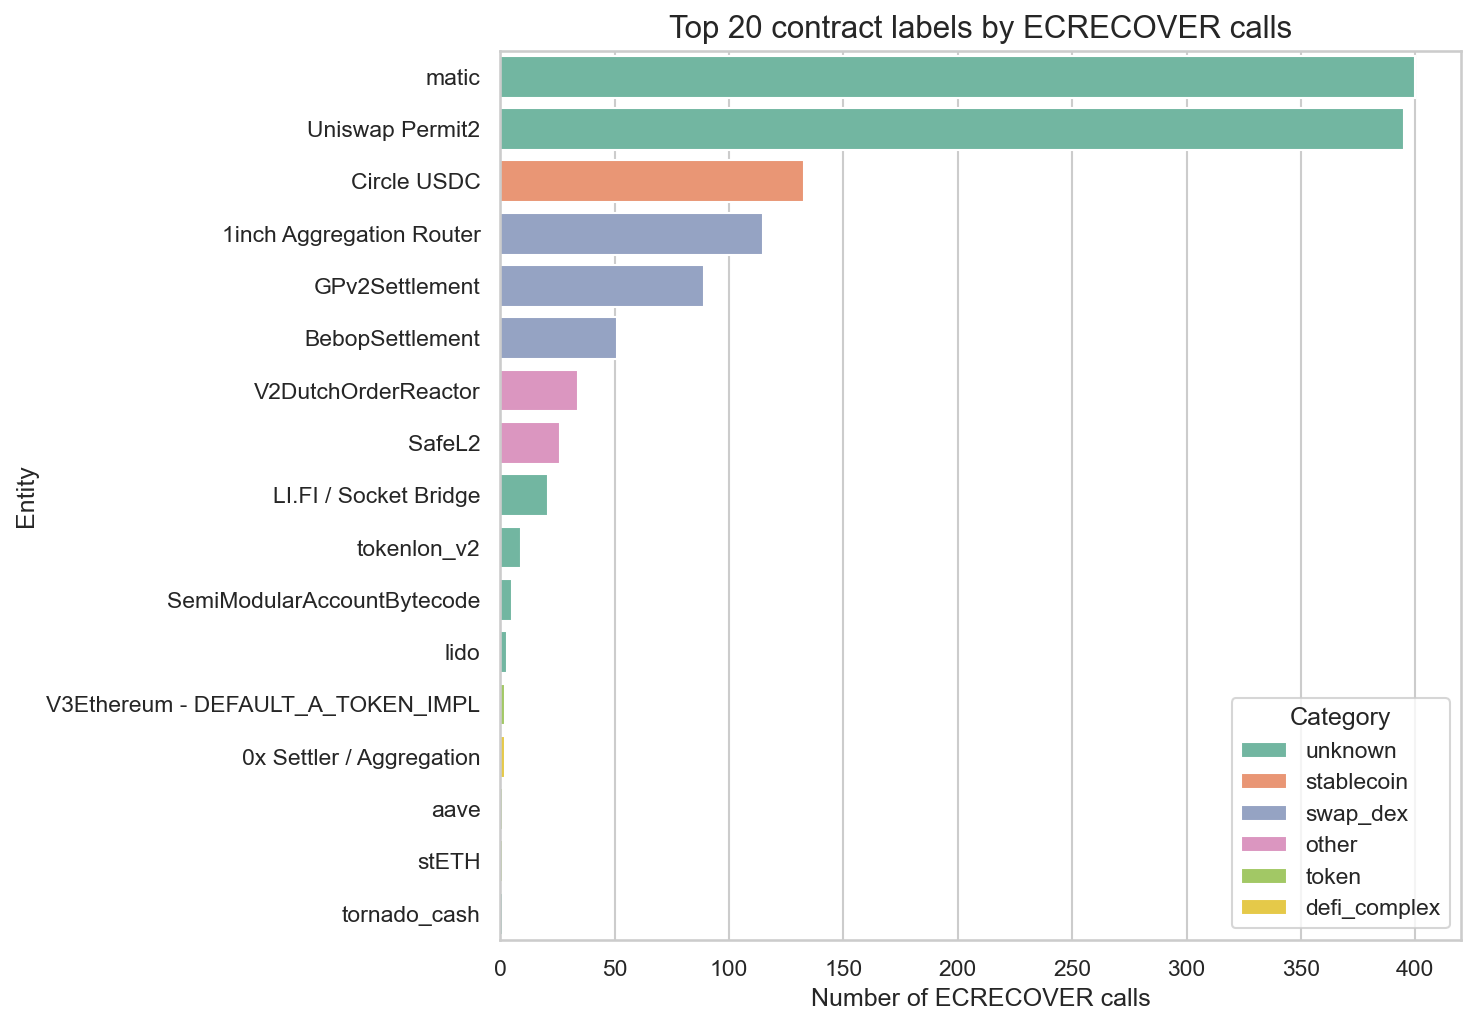

In [53]:
top_n = 20
top_entities_df = (
    entity_summary_df.drop(index="unlabelled", errors="ignore")
    .head(top_n)
    .reset_index()
)

plt.figure(figsize=(10, 7))
sns.barplot(data=top_entities_df, y="entity", x="n_calls", hue="category", dodge=False)
plt.title(f"Top {top_n} contract labels by ECRECOVER calls")
plt.xlabel("Number of ECRECOVER calls")
plt.ylabel("Entity")
plt.legend(title="Category", loc="lower right")
plt.tight_layout()
plt.show()

,entity_category,n_calls,n_txs,pct_calls
0,unlabelled,12178,4969,90.44
1,unknown,834,431,6.19
2,swap_dex,255,234,1.89
3,stablecoin,133,133,0.99
4,other,60,59,0.45
5,token,4,4,0.03
6,defi_complex,2,2,0.01


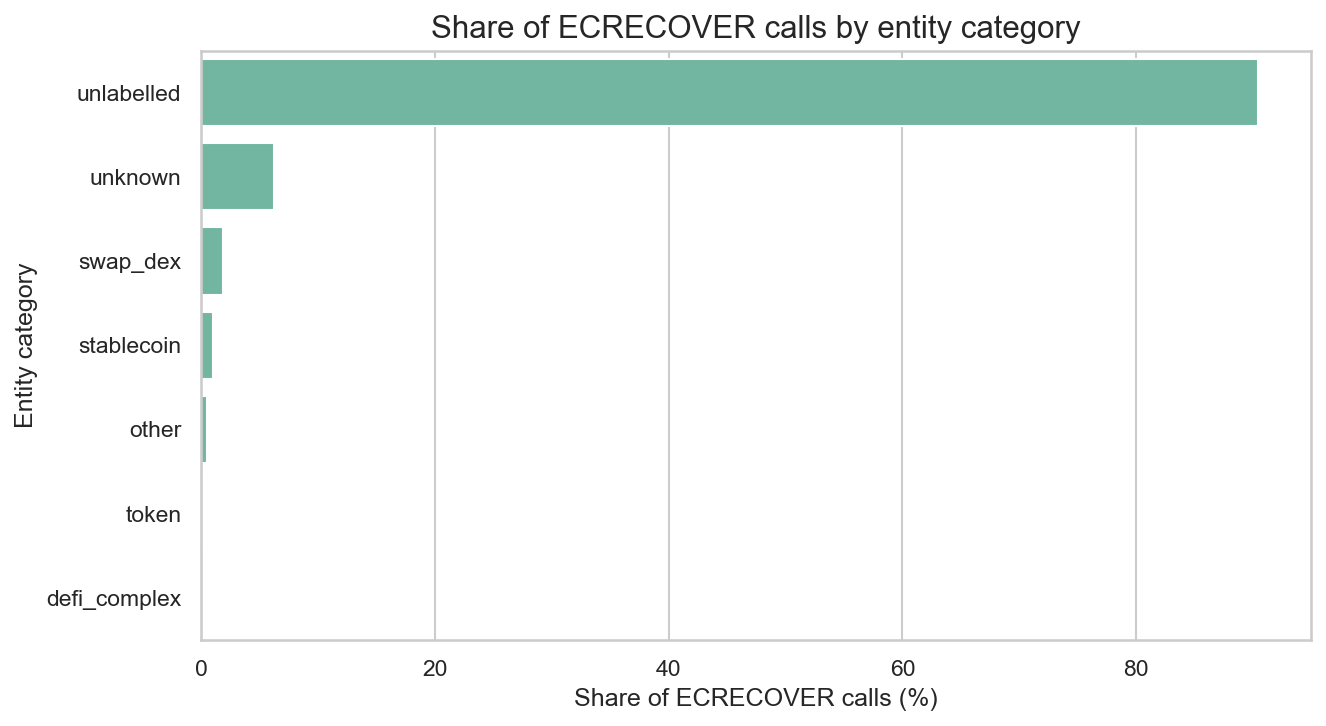

In [54]:
category_df = (
    labelled_df.assign(
        entity_category=labelled_df["entity_category"].fillna("unlabelled")
    )
    .groupby("entity_category")
    .agg(n_calls=("call_frame_id", "size"), n_txs=("transaction_hash", "nunique"))
    .sort_values("n_calls", ascending=False)
    .reset_index()
)
category_df["pct_calls"] = (100 * category_df["n_calls"] / len(labelled_df)).round(2)
display(category_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_df, y="entity_category", x="pct_calls", color=sns.color_palette()[0]
)
plt.title("Share of ECRECOVER calls by entity category")
plt.xlabel("Share of ECRECOVER calls (%)")
plt.ylabel("Entity category")
plt.tight_layout()
plt.show()

### 5.1 Top unlabelled callers

The highest-volume context addresses with no label in the cache. These are the candidates to label by hand (or via a new label source) before expanding the sample.

In [55]:
unlabelled_df = (
    labelled_df[labelled_df["entity"].isna()]
    .groupby("context_address")
    .agg(
        n_calls=("call_frame_id", "size"),
        n_txs=("transaction_hash", "nunique"),
        n_parent_target_addresses=("parent_target_address", "nunique"),
        top_parent_target_address=("parent_target_address", lambda s: s.mode().iat[0]),
        top_tx_to_address=("tx_to_address", lambda s: s.mode().iat[0]),
        top_tx_to_label=(
            "tx_to_label",
            lambda s: s.mode().iat[0] if s.notna().any() else None,
        ),
    )
    .sort_values("n_calls", ascending=False)
)
unlabelled_df["pct_calls"] = (100 * unlabelled_df["n_calls"] / len(labelled_df)).round(
    2
)
display(unlabelled_df.head(25))

,n_calls,n_txs,n_parent_target_addresses,top_parent_target_address,top_tx_to_address,top_tx_to_label,pct_calls
context_address,,,,,,,
0xe37a2663cc9c119ba41572c40fab0bbb23a5402f,2652,91,2,0xc9d215533ab9397950a775f037f70cf56d646c5d,0xe37a2663cc9c119ba41572c40fab0bbb23a5402f,None,19.69
0x91ff8bbd8ebb07893010d50a48a1609e5ebd8e34,463,58,1,0x516f010c9ab452d70e0c6f78b9e698249a66d2ac,0x91ff8bbd8ebb07893010d50a48a1609e5ebd8e34,None,3.44
0x777777777777aec03fd955926dbf81597e66834c,345,322,1,0x777777777777aec03fd955926dbf81597e66834c,0x0000000071727de22e5e9d8baf0edac6f37da032,ERC-4337 EntryPoint v0.7,2.56
0x0000000aa232009084bd71a5797d089aa4edfad4,317,229,1,0x0000000aa232009084bd71a5797d089aa4edfad4,0x0000000aa232009084bd71a5797d089aa4edfad4,None,2.35
0x589dedbd617e0cbcb916a9223f4d1300c294236b,286,143,1,0x589dedbd617e0cbcb916a9223f4d1300c294236b,0x589dedbd617e0cbcb916a9223f4d1300c294236b,None,2.12
0x81d40f21f12a8f0e3252bccb954d722d4c464b64,278,137,1,0xa30c41865729c248067704d4db9f38385cbe1186,0x81d40f21f12a8f0e3252bccb954d722d4c464b64,ERC-4337 EntryPoint v0.7,2.06
0x26d3681dfc9e4c8c79cfbf461adec8a21d5d73c5,252,42,1,0x26d3681dfc9e4c8c79cfbf461adec8a21d5d73c5,0x26d3681dfc9e4c8c79cfbf461adec8a21d5d73c5,None,1.87
0x8f10b468b06c6fd214b65f87778827f7d113f996,235,233,2,0xd7a5c6b52756e795f680b0f7e0c2f21281dde6ef,0x6131b5fae19ea4f9d964eac0408e4408b66337b5,MetaAggregationRouter v2,1.75
0x0000000000000068f116a894984e2db1123eb395,230,96,1,0x0000000000000068f116a894984e2db1123eb395,0x0000000000000068f116a894984e2db1123eb395,ERC-4337 EntryPoint v0.7,1.71


### 5.2 Calls per transaction

Observed `ECRECOVER` invocations per transaction, including failures and reverted execution. This is not a count of successfully verified signatures. Batched verifiers can appear in the right tail.

In [56]:
calls_per_tx_df = (
    labelled_df.groupby("transaction_hash")
    .agg(n_calls=("call_frame_id", "size"), tx_to_address=("tx_to_address", "first"))
    .reset_index()
)
display(
    calls_per_tx_df["n_calls"]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(2)
    .to_frame()
)

,n_calls
count,5529.00
mean,2.44
std,7.22
min,1.00
50%,1.00
90%,3.00
99%,33.00
max,231.00


## 6. ECRECOVER Deprecation Dependencies

To plan a migration, start with **parent targets**: they identify the contracts that directly invoke ECRECOVER and are candidates for code changes. Use **context addresses** to measure how many distinct accounts depend on that code, and **transaction destinations** to identify the entry contracts used by affected transactions.

For `Proxy → DELEGATECALL Implementation → ECRECOVER`, the implementation is the parent target and the proxy is the context. Many proxies can therefore appear under one implementation. For `Router → Permit2 → ECRECOVER`, Permit2 is both parent target and context; it is counted once, and its default label attribution is `parent_target`.

The table ranks individual parent addresses by call volume, then number of distinct contexts. It retains separate addresses even when they share a label. `n_calls_in_other_contexts` counts calls where the parent target differs from the context, including both DELEGATECALL and CALLCODE. A transaction or context can appear under multiple parents, so their distinct counts must not be summed across rows. Each ECRECOVER invocation belongs to exactly one parent, except direct precompile transactions.

**Interpretation:** this identifies observed dependencies, not proven breakage. Establish actual failures by replaying transactions under the proposed deprecation behavior, including any fallback handling. Resolve EIP-7702 code addresses before deciding which implementation needs changing. Label ownership is an outreach clue, subject to the cache's metadata limitations. Direct transactions to the precompile have no parent and are reported separately.


In [57]:
def build_parent_dependency_summary(df):
    """Rank invoking parent targets independently of the default entity attribution."""
    contract_calls = df.loc[~df["is_direct_tx"]].copy()
    contract_calls["other_context"] = contract_calls["parent_target_address"].ne(
        contract_calls["context_address"]
    )
    summary = (
        contract_calls.groupby("parent_target_address")
        .agg(
            label=("parent_label", "first"),
            owner_project=("parent_owner_project", "first"),
            label_source=("parent_source", "first"),
            n_calls=("call_frame_id", "size"),
            n_txs=("transaction_hash", "nunique"),
            n_context_addresses=("context_address", "nunique"),
            n_tx_to_addresses=("tx_to_address", "nunique"),
            n_calls_in_other_contexts=("other_context", "sum"),
        )
        .sort_values(["n_calls", "n_context_addresses"], ascending=False)
    )
    # Denominator includes direct precompile transactions, as in the other summaries.
    summary["pct_all_calls"] = (100 * summary["n_calls"] / len(df)).round(2)
    return summary


parent_dependency_df = build_parent_dependency_summary(labelled_df)
print(f"Direct precompile transactions (excluded from parent ranking): {labelled_df['is_direct_tx'].sum():,}")
display(parent_dependency_df.head(25))


Direct precompile transactions (excluded from parent ranking): 0


,label,owner_project,label_source,n_calls,n_txs,n_context_addresses,n_tx_to_addresses,n_calls_in_other_contexts,pct_all_calls
parent_target_address,,,,,,,,,
0xc9d215533ab9397950a775f037f70cf56d646c5d,None,None,None,2574,52,1,3,2574,19.11
0x516f010c9ab452d70e0c6f78b9e698249a66d2ac,None,None,None,463,58,1,4,463,3.44
0x428d1067b33b2bca826cf66344dbecbd5aa6506e,None,None,None,400,4,1,1,400,2.97
0x000000000022d473030f116ddee9f6b43ac78ba3,Uniswap Permit2,None,manual,395,391,1,46,0,2.93
0x777777777777aec03fd955926dbf81597e66834c,None,None,None,345,322,1,1,0,2.56
0x0000000aa232009084bd71a5797d089aa4edfad4,None,None,None,317,229,1,1,0,2.35
0x589dedbd617e0cbcb916a9223f4d1300c294236b,None,None,None,286,143,1,1,0,2.12
0xa30c41865729c248067704d4db9f38385cbe1186,None,None,None,278,137,1,11,278,2.06
0x26d3681dfc9e4c8c79cfbf461adec8a21d5d73c5,None,None,None,252,42,1,1,0,1.87


### 6.1 Inspect the Accounts and Entry Contracts Depending on a Parent

Set `focus_parent_address` to any address from the parent ranking. It defaults to the highest-volume parent. The first table lists its contexts (the accounts running that code); the second lists its transaction destinations (the entry contracts). These are separate views of the same calls, not additional calls. Counts describe only this sample and do not enumerate every deployed account that might depend on the implementation.


In [58]:
# Replace with a parent target address to inspect a specific dependency.
focus_parent_address = parent_dependency_df.index[0] if not parent_dependency_df.empty else None
parent_calls_df = labelled_df.loc[
    labelled_df["parent_target_address"].eq(focus_parent_address)
]
context_dependency_df = (
    parent_calls_df.groupby("context_address")
    .agg(label=("context_label", "first"),
         owner_project=("context_owner_project", "first"),
         n_calls=("call_frame_id", "size"),
         n_txs=("transaction_hash", "nunique"),
         n_tx_to_addresses=("tx_to_address", "nunique"))
    .sort_values("n_calls", ascending=False)
)
entry_dependency_df = (
    parent_calls_df.groupby("tx_to_address")
    .agg(label=("tx_to_label", "first"),
         owner_project=("tx_to_owner_project", "first"),
         n_calls=("call_frame_id", "size"),
         n_txs=("transaction_hash", "nunique"),
         n_context_addresses=("context_address", "nunique"))
    .sort_values("n_calls", ascending=False)
)
print(f"Selected parent target: {focus_parent_address}")
display(context_dependency_df.head(25))
display(entry_dependency_df.head(25))


Selected parent target: 0xc9d215533ab9397950a775f037f70cf56d646c5d


,label,owner_project,n_calls,n_txs,n_tx_to_addresses
context_address,,,,,
0xe37a2663cc9c119ba41572c40fab0bbb23a5402f,None,None,2574,52,3


,label,owner_project,n_calls,n_txs,n_context_addresses
tx_to_address,,,,,
0xe37a2663cc9c119ba41572c40fab0bbb23a5402f,None,None,1320,40,1
0xba08ef4193a12be61a768fd96e625b541702828f,None,None,858,6,1
0x1fb0974eb1ce10ddd6b71f7cac57ddc3fe2466cc,None,None,396,6,1


## Summary

The following summary is generated from the current run.

In [59]:
n_calls = len(labelled_df)
quantiles = calls_per_tx_df["n_calls"].quantile([0.5, 0.99])
display(Markdown(f"""
Sample: {start_date_str} to {end_date_str} UTC; blocks {min_block:,}–{max_block:,} ({n_blocks:,} block numbers).

| Metric | Value |
|---|---:|
| Observed ECRECOVER calls | {n_calls:,} ({n_calls / n_blocks:.1f} per block) |
| Transactions with ≥ 1 call | {n_txs:,} |
| Calls per tx: median / p99 / max | {quantiles.loc[0.5]:g} / {quantiles.loc[0.99]:g} / {calls_per_tx_df['n_calls'].max():,} |
| Unique parent targets | {labelled_df["parent_target_address"].nunique():,} |
| Unique context addresses | {labelled_df['context_address'].nunique():,} |
| Calls with parent target ≠ context | {different_context.sum():,} ({100 * different_context.mean():.1f}%) |
| Direct transactions to the precompile | {labelled_df['is_direct_tx'].sum():,} |
| Calls matched to a contract label | {100 * labelled_df['entity'].notna().mean():.1f}% |

Per-block rates assume complete source coverage of the selected block range. The deprecation tables in Section 6 identify observed dependencies, not confirmed failures. Rankings inherit the cache's coverage and metadata limitations; parent-target fallback identifies shared implementations. EIP-7702 implementation addresses are not resolved.
"""))


Sample: 2026-10-27 00:00:00 to 2026-10-27 01:00:00 UTC; blocks 26,280,314–26,280,612 (299 block numbers).

| Metric | Value |
|---|---:|
| Observed ECRECOVER calls | 13,466 (45.0 per block) |
| Transactions with ≥ 1 call | 5,529 |
| Calls per tx: median / p99 / max | 1 / 33 / 231 |
| Unique parent targets | 1,564 |
| Unique context addresses | 1,790 |
| Calls with parent target ≠ context | 6,143 (45.6%) |
| Direct transactions to the precompile | 0 |
| Calls matched to a contract label | 9.6% |

Per-block rates assume complete source coverage of the selected block range. The deprecation tables in Section 6 identify observed dependencies, not confirmed failures. Rankings inherit the cache's coverage and metadata limitations; parent-target fallback identifies shared implementations. EIP-7702 implementation addresses are not resolved.
